1.การเตรียมข้อมูล

In [ ]:
# ใส่เครื่องหมาย ! ข้างหน้าเพื่อสั่งงาน Terminal ผ่าน Jupyter
!pip install kagglehub

In [7]:
import kagglehub
import pandas as pd
import os

# 1.1 ดาวน์โหลดข้อมูลโดยอัตโนมัติ
path = kagglehub.dataset_download("azminetoushikwasi/-lionel-messi-all-club-goals")
csv_path = os.path.join(path, "data.csv")
df = pd.read_csv(csv_path)

# 1.2 การทำความสะอาดข้อมูล (Data Cleaning)
# แปลงคอลัมน์วันที่และจัดการค่าว่างในส่วนของคนส่งบอล (Assist) [cite: 1]
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Goal_assist'] = df['Goal_assist'].fillna('Solo')

# 1.3 การวิศวกรรมฟีเจอร์ (Feature Engineering)
# สร้าง Label สำหรับทำนาย: 1 หากยิงด้วยเท้าซ้าย (Left-footed shot), 0 หากไม่ใช่ 
df['Is_Left_Foot'] = df['Type'].apply(lambda x: 1 if 'Left-footed' in str(x) else 0)
df['Minute_Clean'] = pd.to_numeric(df['Minute'].astype(str).str.replace('+', ''), errors='coerce').fillna(0)

C:\Users\USER\AppData\Local\Temp\ipykernel_1272\966207112.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


2.การทำการฝึกแบบจำลอง (Model Training)

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# แปลงข้อมูลตัวอักษรเป็นตัวเลข
le = LabelEncoder()
df['Pos_Encoded'] = le.fit_transform(df['Playing_Position'].astype(str))
df['Venue_Encoded'] = le.fit_transform(df['Venue'])

# เลือกตัวแปรต้น (Features) และตัวแปรตาม (Target)
X = df[['Pos_Encoded', 'Venue_Encoded', 'Minute_Clean']]
y = df['Is_Left_Foot']

# แบ่งชุดข้อมูลสำหรับฝึกสอน 80% และทดสอบ 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ฝึกสอนแบบจำลอง
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

3. การวัดผล (Evaluation)

In [9]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)
print(f"ความแม่นยำของแบบจำลอง (Accuracy): {accuracy_score(y_test, y_pred):.2f}")
print("\nรายงานผลการทดสอบ:")
print(classification_report(y_test, y_pred))

ความแม่นยำของแบบจำลอง (Accuracy): 0.52

รายงานผลการทดสอบ:
              precision    recall  f1-score   support

           0       0.37      0.27      0.31        56
           1       0.59      0.69      0.64        85

    accuracy                           0.52       141
   macro avg       0.48      0.48      0.47       141
weighted avg       0.50      0.52      0.51       141



C:\Users\USER\AppData\Local\Temp\ipykernel_1272\2279775670.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_opponents.values, y=top_opponents.index, palette='viridis')


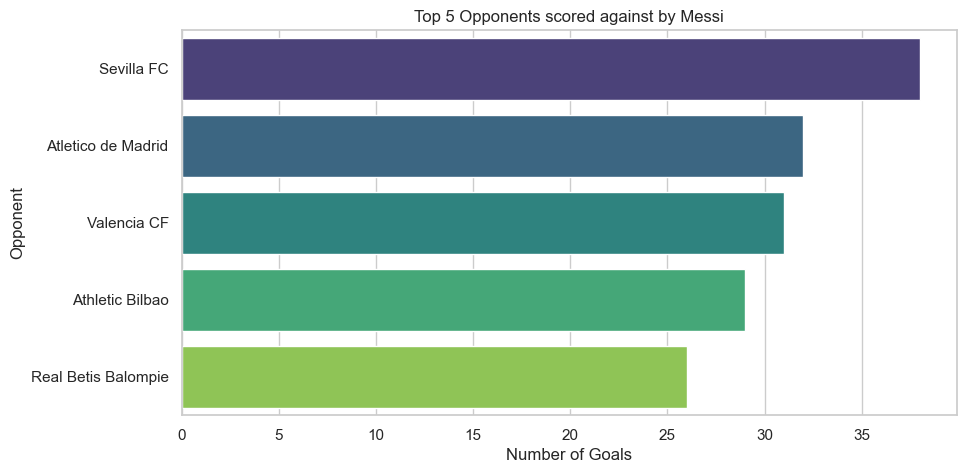

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าสไตล์กราฟ
sns.set_theme(style="whitegrid")

# แสดง 5 อันดับคู่แข่งที่ถูกทำประตูใส่มากที่สุด
plt.figure(figsize=(10, 5))
top_opponents = df['Opponent'].value_counts().head(5)
sns.barplot(x=top_opponents.values, y=top_opponents.index, palette='viridis')
plt.title('Top 5 Opponents scored against by Messi')
plt.xlabel('Number of Goals')
plt.show()